
# AI Quant Research Lab
## Stage 2: Strategy Development and Backtesting

Objective:
Test whether a simple moving-average strategy can outperform
a buy-and-hold benchmark after transaction costs.

Asset: AAPL
Data source: Yahoo Finance
Research period: January 2021 – December 2025


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Download the data independently so this notebook is reproducible
data = yf.download(
    "AAPL",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

if data.empty:
    raise ValueError("No data downloaded. Check your internet connection.")

# Handle Yahoo Finance's possible multi-level column names
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.loc[:, ~data.columns.duplicated()].sort_index()

if "Adj Close" not in data.columns:
    raise ValueError("Adjusted closing prices are unavailable.")

data = data[["Adj Close"]].rename(columns={"Adj Close": "Price"})
data = data.dropna()

# Daily returns
data["Return"] = data["Price"].pct_change(fill_method=None)

# Moving averages
data["SMA_20"] = data["Price"].rolling(20).mean()
data["SMA_50"] = data["Price"].rolling(50).mean()

print("Dataset ready.")
display(data.tail())


Dataset ready.


Price,Price,Return,SMA_20,SMA_50
Date,,,,
2025-12-24,273.066711,0.005324,276.399652,270.219038
2025-12-26,272.657837,-0.001497,276.192715,270.703748
2025-12-29,273.016876,0.001317,275.938907,271.233300
2025-12-30,272.338684,-0.002484,275.439265,271.652844
2025-12-31,271.122009,-0.004468,274.724710,271.849788


In [2]:

# Signal observed at the end of each trading session
data["Signal"] = (
    data["SMA_20"] > data["SMA_50"]
).astype(int)

# Trade using yesterday's signal to avoid look-ahead bias
data["Position"] = data["Signal"].shift(1).fillna(0)

# Strategy return before transaction costs
data["Strategy_Return_Gross"] = (
    data["Position"] * data["Return"]
)

# Buy-and-hold benchmark
data["Benchmark_Return"] = data["Return"]

# Turnover: 1 when entering or exiting a position
data["Turnover"] = (
    data["Position"].diff().abs()
    .fillna(data["Position"].abs())
)

# Assumed one-way transaction cost: 0.10% per trade
transaction_cost = 0.001

data["Strategy_Return"] = (
    data["Strategy_Return_Gross"]
    - data["Turnover"] * transaction_cost
)

# Remove rows where the moving averages or returns aren't available
backtest = data.dropna(
    subset=["Return", "SMA_20", "SMA_50"]
).copy()

print("Backtest observations:", len(backtest))
print("Assumed transaction cost:", transaction_cost * 100, "% per position change")
display(backtest.tail())


Backtest observations: 1206
Assumed transaction cost: 0.1 % per position change


Price,Price,Return,SMA_20,SMA_50,Signal,Position,Strategy_Return_Gross,Benchmark_Return,Turnover,Strategy_Return
Date,,,,,,,,,,
2025-12-24,273.066711,0.005324,276.399652,270.219038,1,1.0,0.005324,0.005324,0.0,0.005324
2025-12-26,272.657837,-0.001497,276.192715,270.703748,1,1.0,-0.001497,-0.001497,0.0,-0.001497
2025-12-29,273.016876,0.001317,275.938907,271.233300,1,1.0,0.001317,0.001317,0.0,0.001317
2025-12-30,272.338684,-0.002484,275.439265,271.652844,1,1.0,-0.002484,-0.002484,0.0,-0.002484
2025-12-31,271.122009,-0.004468,274.724710,271.849788,1,1.0,-0.004468,-0.004468,0.0,-0.004468


In [3]:

def calculate_metrics(returns, periods_per_year=252):
    returns = returns.dropna()

    if len(returns) == 0:
        return {}

    # Compound returns rather than simply adding percentages
    equity = (1 + returns).cumprod()

    total_return = equity.iloc[-1] - 1

    years = len(returns) / periods_per_year
    cagr = (
        equity.iloc[-1] ** (1 / years) - 1
        if years > 0 and equity.iloc[-1] > 0
        else np.nan
    )

    annual_volatility = (
        returns.std(ddof=1) * np.sqrt(periods_per_year)
    )

    sharpe = (
        returns.mean() / returns.std(ddof=1)
        * np.sqrt(periods_per_year)
        if returns.std(ddof=1) > 0
        else np.nan
    )

    drawdown = equity / equity.cummax() - 1
    max_drawdown = drawdown.min()

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Annualized Volatility": annual_volatility,
        "Sharpe Ratio (0% risk-free)": sharpe,
        "Maximum Drawdown": max_drawdown
    }


strategy_metrics = calculate_metrics(
    backtest["Strategy_Return"]
)

benchmark_metrics = calculate_metrics(
    backtest["Benchmark_Return"]
)

comparison = pd.DataFrame({
    "Moving Average Strategy": strategy_metrics,
    "Buy and Hold": benchmark_metrics
})

display(comparison.style.format("{:.2%}", subset=pd.IndexSlice[
    ["Total Return", "CAGR", "Annualized Volatility", "Maximum Drawdown"], :
]).format("{:.2f}", subset=pd.IndexSlice[
    ["Sharpe Ratio (0% risk-free)"], :
]))


,Moving Average Strategy,Buy and Hold
Total Return,33.15%,124.90%
CAGR,6.16%,18.45%
Annualized Volatility,18.19%,27.57%
Sharpe Ratio (0% risk-free),0.42,0.75
Maximum Drawdown,-29.80%,-33.36%


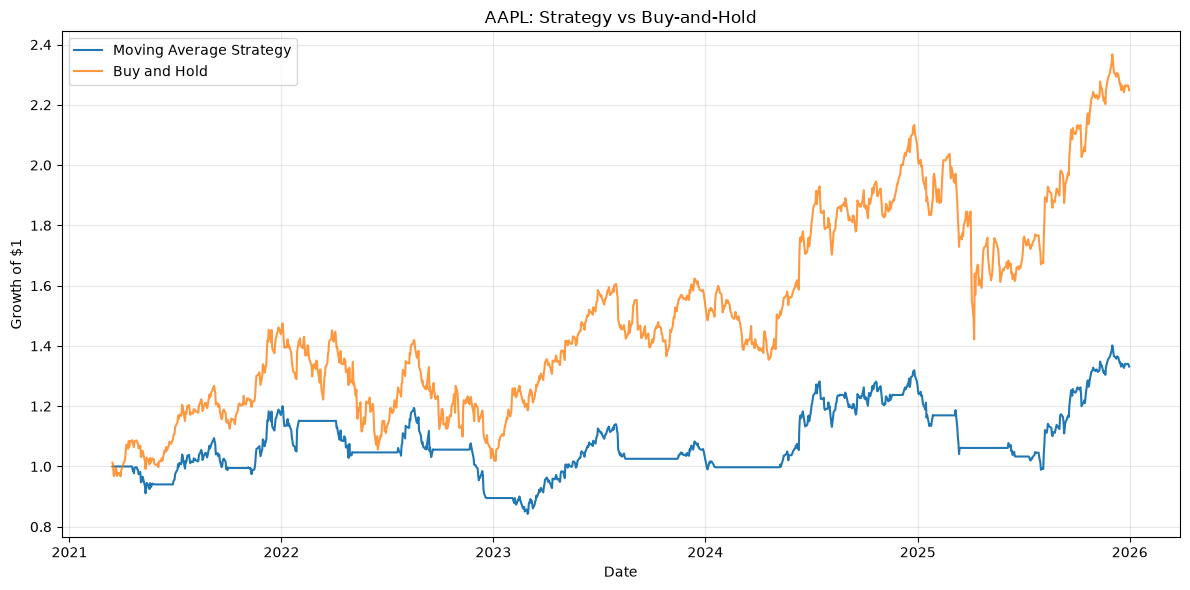

In [4]:

strategy_equity = (
    1 + backtest["Strategy_Return"]
).cumprod()

benchmark_equity = (
    1 + backtest["Benchmark_Return"]
).cumprod()

plt.figure(figsize=(12, 6))

plt.plot(
    backtest.index,
    strategy_equity,
    label="Moving Average Strategy"
)

plt.plot(
    backtest.index,
    benchmark_equity,
    label="Buy and Hold",
    alpha=0.8
)

plt.title("AAPL: Strategy vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# STAGE 3: ROBUSTNESS TESTING

transaction_cost = 0.001  # 0.10% per position change

# Different parameter combinations to test
parameter_sets = [
    (10, 30),
    (20, 50),
    (30, 100),
    (50, 150)
]

# Use the same evaluation period for every strategy.
# The longest moving average is 150 sessions.
common_start = data["Price"].rolling(150).mean().first_valid_index()

if common_start is None:
    raise ValueError("Not enough price history for robustness testing.")

test_data = data.loc[common_start:].copy()

results = []

for short_window, long_window in parameter_sets:

    # Calculate moving averages using historical prices
    short_ma = data["Price"].rolling(short_window).mean()
    long_ma = data["Price"].rolling(long_window).mean()

    # Generate signal, then trade on the following session
    signal = (short_ma > long_ma).astype(int)
    position = signal.shift(1).fillna(0)

    # Calculate returns and trading costs
    asset_returns = data["Price"].pct_change(fill_method=None)

    gross_returns = position * asset_returns

    turnover = position.diff().abs()
    turnover.iloc[0] = abs(position.iloc[0])

    net_returns = gross_returns - turnover * transaction_cost

    # Restrict every strategy and the benchmark to identical valid dates
    evaluation_returns = pd.DataFrame({
        "Strategy": net_returns,
        "Benchmark": asset_returns
    }).loc[test_data.index].dropna()

    net_returns = evaluation_returns["Strategy"]
    benchmark_returns = evaluation_returns["Benchmark"]

    # Calculate performance metrics
    metrics = calculate_metrics(net_returns)
    benchmark = calculate_metrics(benchmark_returns)

    results.append({
        "Short MA": short_window,
        "Long MA": long_window,
        "Strategy Return": metrics["Total Return"],
        "Strategy CAGR": metrics["CAGR"],
        "Strategy Sharpe": metrics["Sharpe Ratio (0% risk-free)"],
        "Strategy Max Drawdown": metrics["Maximum Drawdown"],
        "Benchmark Return": benchmark["Total Return"],
        "Number of Position Changes": int(
            turnover.loc[net_returns.index].sum()
        )
    })

robustness_results = pd.DataFrame(results)

print("ROBUSTNESS TEST RESULTS")
display(
    robustness_results.style.format({
        "Strategy Return": "{:.2%}",
        "Strategy CAGR": "{:.2%}",
        "Strategy Sharpe": "{:.2f}",
        "Strategy Max Drawdown": "{:.2%}",
        "Benchmark Return": "{:.2%}"
    })
)


ROBUSTNESS TEST RESULTS


,Short MA,Long MA,Strategy Return,Strategy CAGR,Strategy Sharpe,Strategy Max Drawdown,Benchmark Return,Number of Position Changes
0,10,30,22.30%,4.69%,0.34,-27.95%,89.30%,41
1,20,50,29.88%,6.14%,0.42,-29.80%,89.30%,26
2,30,100,33.24%,6.76%,0.44,-31.41%,89.30%,12
3,50,150,11.79%,2.57%,0.23,-28.40%,89.30%,11


In [6]:

# STAGE 4: OUT-OF-SAMPLE EVALUATION

# We keep the original 20-day / 50-day strategy fixed.
# We do not optimize its parameters using the test period.

short_window = 20
long_window = 50
transaction_cost = 0.001  # 0.10% per position change

# Rebuild the strategy using the price history
prices = data["Price"].copy()

returns = prices.pct_change(fill_method=None)

short_ma = prices.rolling(short_window).mean()
long_ma = prices.rolling(long_window).mean()

# Signal available at each day's close
signal = (short_ma > long_ma).astype(int)

# Position held during the following trading session
position = signal.shift(1).fillna(0)

# Apply transaction costs when entering or exiting
turnover = position.diff().abs()
turnover.iloc[0] = abs(position.iloc[0])

strategy_returns = (
    position * returns
    - turnover * transaction_cost
)

# Define chronological research and evaluation periods
train_start = "2021-01-01"
test_start = "2024-01-01"
test_end = "2026-01-01"

# The test period begins in 2024 and ends in 2025.
test_mask = (
    (prices.index >= test_start)
    & (prices.index < test_end)
)

# Keep only dates where strategy and benchmark returns exist
test_returns = strategy_returns.loc[test_mask].dropna()
test_benchmark = returns.loc[test_returns.index]

if len(test_returns) == 0:
    raise ValueError("No test-period returns available.")

# Report the actual evaluation period
print("OUT-OF-SAMPLE EVALUATION")
print("-" * 40)
print("Training period:", train_start, "to 2023-12-31")
print("Test period:", test_returns.index.min().date(),
      "to", test_returns.index.max().date())
print("Test observations:", len(test_returns))

# Calculate performance on the test period only
test_strategy_metrics = calculate_metrics(test_returns)
test_benchmark_metrics = calculate_metrics(test_benchmark)

test_comparison = pd.DataFrame({
    "Strategy (Net of Costs)": test_strategy_metrics,
    "Buy and Hold": test_benchmark_metrics
})

display(
    test_comparison.style.format({
        "Strategy (Net of Costs)": "{:.2%}",
        "Buy and Hold": "{:.2%}"
    }, subset=pd.IndexSlice[
        ["Total Return", "CAGR", "Annualized Volatility",
         "Maximum Drawdown"], :
    ]).format(
        "{:.2f}",
        subset=pd.IndexSlice[["Sharpe Ratio (0% risk-free)"], :]
    )
)


OUT-OF-SAMPLE EVALUATION
----------------------------------------
Training period: 2021-01-01 to 2023-12-31
Test period: 2024-01-02 to 2025-12-31
Test observations: 502


,Strategy (Net of Costs),Buy and Hold
Total Return,26.54%,42.54%
CAGR,12.54%,19.47%
Annualized Volatility,18.52%,27.99%
Sharpe Ratio (0% risk-free),0.73,0.77
Maximum Drawdown,-25.03%,-33.36%


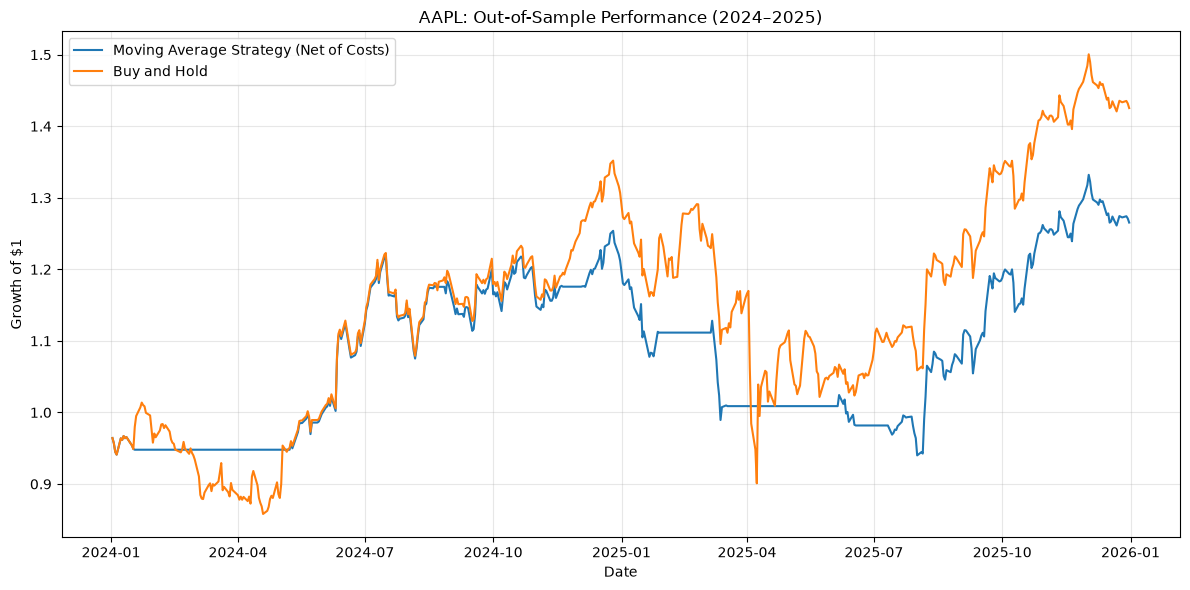

In [7]:

strategy_equity_test = (1 + test_returns).cumprod()
benchmark_equity_test = (1 + test_benchmark).cumprod()

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_equity_test.index,
    strategy_equity_test,
    label="Moving Average Strategy (Net of Costs)"
)

plt.plot(
    benchmark_equity_test.index,
    benchmark_equity_test,
    label="Buy and Hold"
)

plt.title("AAPL: Out-of-Sample Performance (2024–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

# STAGE 5: STRATEGY FALSIFICATION ENGINE

# Keep the same evaluation dates as the previous out-of-sample test
test_start = "2024-01-01"
test_end = "2026-01-01"

test_mask = (
    (prices.index >= test_start)
    & (prices.index < test_end)
)

test_positions = position.loc[test_mask]
test_asset_returns = returns.loc[test_mask]

# Calculate position changes using the complete position history.
# This preserves the correct turnover when the test period begins.
all_turnover = position.diff().abs()
all_turnover.iloc[0] = abs(position.iloc[0])

test_turnover = all_turnover.loc[test_mask]

# Use one shared set of valid test dates
valid = (
    test_positions.notna()
    & test_asset_returns.notna()
    & test_turnover.notna()
)

test_positions = test_positions.loc[valid]
test_asset_returns = test_asset_returns.loc[valid]
test_turnover = test_turnover.loc[valid]

# 1. Transaction-cost stress test
cost_levels = [0.0, 0.001, 0.0025, 0.005]

cost_results = []

for cost in cost_levels:
    net_returns = (
        test_positions * test_asset_returns
        - test_turnover * cost
    )

    metrics = calculate_metrics(net_returns)

    cost_results.append({
        "One-way cost": cost,
        "Total return": metrics["Total Return"],
        "CAGR": metrics["CAGR"],
        "Sharpe ratio": metrics["Sharpe Ratio (0% risk-free)"],
        "Maximum drawdown": metrics["Maximum Drawdown"]
    })

cost_table = pd.DataFrame(cost_results)

print("TEST 1: TRANSACTION-COST STRESS TEST")
display(cost_table.style.format({
    "One-way cost": "{:.2%}",
    "Total return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Sharpe ratio": "{:.2f}",
    "Maximum drawdown": "{:.2%}"
}))

# 2. Return concentration test at 0.10% one-way costs
base_returns = (
    test_positions * test_asset_returns
    - test_turnover * 0.001
)

positive_returns = base_returns[base_returns > 0].sort_values(
    ascending=False
)

total_positive_return = positive_returns.sum()

top_5_share = (
    positive_returns.head(5).sum() / total_positive_return
    if total_positive_return > 0
    else np.nan
)

print("\nTEST 2: RETURN CONCENTRATION")
print("Number of positive-return days:", len(positive_returns))
print("Share of positive daily returns from top 5 days:",
      f"{top_5_share:.2%}" if pd.notna(top_5_share) else "N/A")

# 3. Compare the strategy with buy-and-hold
benchmark_metrics = calculate_metrics(test_asset_returns)
strategy_metrics = calculate_metrics(base_returns)

print("\nTEST 3: STRATEGY VS BUY-AND-HOLD")
comparison = pd.DataFrame({
    "Strategy": strategy_metrics,
    "Buy and Hold": benchmark_metrics
})

display(comparison)


TEST 1: TRANSACTION-COST STRESS TEST


,One-way cost,Total return,CAGR,Sharpe ratio,Maximum drawdown
0,0.00%,28.06%,13.22%,0.76,-24.58%
1,0.10%,26.54%,12.54%,0.73,-25.03%
2,0.25%,24.28%,11.53%,0.68,-25.70%
3,0.50%,20.60%,9.86%,0.60,-26.81%



TEST 2: RETURN CONCENTRATION
Number of positive-return days: 174
Share of positive daily returns from top 5 days: 13.94%

TEST 3: STRATEGY VS BUY-AND-HOLD


,Strategy,Buy and Hold
Total Return,0.265364,0.425375
CAGR,0.125412,0.194734
Annualized Volatility,0.185166,0.279870
Sharpe Ratio (0% risk-free),0.730358,0.774223
Maximum Drawdown,-0.250303,-0.333605


In [9]:

# STAGE 6: BEST-DAY DEPENDENCY TEST

# Use the same out-of-sample period and 0.10% transaction cost
base_returns = (
    test_positions * test_asset_returns
    - test_turnover * 0.001
).dropna()

# Identify the five strongest daily strategy returns
best_days = base_returns.nlargest(5)

# Counterfactual: replace those five returns with zero
returns_without_best_days = base_returns.copy()
returns_without_best_days.loc[best_days.index] = 0.0

# Calculate performance for both cases
normal_metrics = calculate_metrics(base_returns)
counterfactual_metrics = calculate_metrics(
    returns_without_best_days
)

dependency_results = pd.DataFrame({
    "Original Strategy": normal_metrics,
    "Without Best 5 Days": counterfactual_metrics
})

print("BEST-DAY DEPENDENCY TEST")
display(dependency_results)

print("\nFive strongest daily strategy returns:")
display(
    best_days.rename("Daily Strategy Return")
    .to_frame()
    .style.format("{:.2%}")
)


BEST-DAY DEPENDENCY TEST


,Original Strategy,Without Best 5 Days
Total Return,0.265364,-0.006761
CAGR,0.125412,-0.003400
Annualized Volatility,0.185166,0.166677
Sharpe Ratio (0% risk-free),0.730358,0.063105
Maximum Drawdown,-0.250303,-0.250303



Five strongest daily strategy returns:


,Daily Strategy Return
Date,
2024-06-11 00:00:00,7.26%
2025-08-06 00:00:00,5.09%
2025-09-22 00:00:00,4.31%
2025-08-08 00:00:00,4.24%
2025-10-20 00:00:00,3.94%


In [ ]:
from pathlib import Path

# Create the reports folder in the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Inspect the variables currently available in this notebook
print("Reports folder:", REPORTS_DIR)
print("\nAvailable backtesting variables:")

for name, value in list(globals().items()):
    if not name.startswith("_") and not callable(value):
        if hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")

In [11]:
# Export Notebook 02 results for the final research report

from pathlib import Path

import pandas as pd

REPORTS_DIR = Path.cwd().parent / "reports" if Path.cwd().name == "notebooks" else Path.cwd() / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

results_to_export = {
    "backtest_comparison": test_comparison,
    "robustness_results": robustness_results,
    "transaction_cost_analysis": cost_table,
    "strategy_dependency_analysis": dependency_results,
}

for filename, result in results_to_export.items():
    output_path = REPORTS_DIR / f"{filename}.csv"

    if isinstance(result, pd.Series):
        result.to_frame().to_csv(output_path)
    else:
        result.to_csv(output_path)

    print(f"Saved: {output_path.name} | Shape: {result.shape}")

print("\nNotebook 02 export complete.")

Saved: backtest_comparison.csv | Shape: (5, 2)
Saved: robustness_results.csv | Shape: (4, 8)
Saved: transaction_cost_analysis.csv | Shape: (4, 5)
Saved: strategy_dependency_analysis.csv | Shape: (5, 2)

Notebook 02 export complete.


## Research Finding: Moving-Average Strategy Falsification

**Asset:** AAPL  
**Evaluation period:** 2024–2025  
**Strategy:** 20-day / 50-day simple moving-average crossover  
**Assumed transaction cost:** 0.10% per position change

### Results

The strategy produced a total return of 26.54%, a CAGR of 12.54%, and a Sharpe ratio of 0.73 after assumed transaction costs. Buy-and-hold returned 42.54%, with a CAGR of 19.47% and a Sharpe ratio of 0.77 over the same period.

The strategy exhibited lower annualized volatility and a smaller maximum drawdown than buy-and-hold, but did not demonstrate superior risk-adjusted performance.

In a counterfactual sensitivity test, replacing the five strongest daily strategy returns with zero reduced total return to −0.68% and the Sharpe ratio to 0.06.

### Conclusion

The strategy's observed profitability was highly sensitive to a small number of exceptional daily returns. This weakens confidence in the robustness of its historical performance and motivates further investigation into return concentration, signal timing, data quality, and out-of-sample generalization.

The best-day test is a diagnostic rather than a realistic alternative trading simulation. These historical results do not establish future profitability.